# E12-H60 - no-counterpart cost valley probe

Executes the pre-registered **E12-H60** record (`### E12-H60 No-counterpart cost valley probe` in
`docs/experiments/wmd-docdistance-experiments.md`).

`NO_COUNTERPART_COST = 0.6` (`src/docdistance/pipeline.py:47`) was placed by scale reasoning and validated
once against a synthetic removal at cheapest cost 1.414, while the field observation recorded in
`DEF-TRANS-1` is a real absorber match at cost 0.76 - only 0.16 above the cut. The hypothesis is that the
matched and the removed cost populations approach each other rather than leaving a clean gap, so hard
rewordings of genuinely matched statements cross 0.6 and are falsely flagged `no_counterpart`.

**Approach**

1. **Kill-gate first** - read `summary.cost_bands[">0.6"]` from the semantic detail JSON of every
   fully-matched pair (gold vs gold-2, v1 vs v2, and werg-a / werg-b / werg-c against their
   back-translations). A zero band on every one of them means the flag never over-fires on
   construction-guaranteed matched content, and the hypothesis is dead before any deletion fixture is built
2. **Cheapest-row-cost readout** on the same pairs - how much headroom sits between the matched upper tail
   and the 0.6 cut
3. **Registered experiment** - matched and removed cost histograms from the paraphrase pairs and from
   deletion variants, and the density valley. Built only if the gate passes
4. **By-product** - independent of the deletion fixture: pool the cheapest-row costs over the 55 ibm
   summary pairs and sweep the cut by +/- 0.15, counting per-statement flag flips
5. **Guardrails** - `V` on the ibm fixture, `smd` and `order_gap` bit-identity under a patched cut on both
   the semantic and the structural detail JSON, and the triangle inequality on the pairwise `smd` matrix

Nothing under `src/`, `docs/`, `tests/` or `data/` is written. Every variant is a read of the shipped
`docdistance.pipeline` entry points; the deletion variants, if built, live only in memory.

## Environment

CPU-only by design: the workstation GPUs are held by foreign jobs, and the shipped default path is the
OpenVINO INT8 encoder, which runs on CPU. CUDA is masked off before any torch import so the SaT segmenter
also resolves to CPU.

In [1]:
import os

# CPU pin: no GPU is available to this run, and the shipped default encoder is OpenVINO INT8 on CPU.
# Masking CUDA before torch is imported makes the SaT segmenter resolve to CPU as well.
os.environ["CUDA_VISIBLE_DEVICES"] = ""
# the notebook's working folder is notebooks/experiments/, so point the readiness gate at the
# repository's own docdistance.json (mmBERT / reranker / NLI OpenVINO INT8 mirrors, modes wmd + wmd-wrt-source)
os.environ["DOCDISTANCE_HOME"] = "/home/lab/workspace/learning/projects/docdistance"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
import warnings

warnings.filterwarnings("ignore")

import torch

print(f"torch {torch.__version__} | cuda visible: {torch.cuda.is_available()} | device: CPU")
print(f"DOCDISTANCE_HOME={os.environ['DOCDISTANCE_HOME']}")

torch 2.11.0+cu130 | cuda visible: False | device: CPU
DOCDISTANCE_HOME=/home/lab/workspace/learning/projects/docdistance


## Imports

In [2]:
import copy
import json
import time
from datetime import datetime, timezone
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import ot
import seaborn as sns
from rich.console import Console
from rich.panel import Panel
from rich.table import Table

import docdistance.pipeline as pipe
from docdistance.distance import SMD_MAX, cost_matrix
from docdistance.pipeline import DocDistance

console = Console()
sns.set_theme(style="whitegrid", context="notebook")
print(f"imports ready | POT {ot.__version__} | docdistance {pipe._VERSION}")

imports ready | POT 0.9.6.post1 | docdistance 1.1.5


## Reproducibility

In [3]:
SEED = 0
np.random.seed(SEED)
print(f"SEED={SEED}")

SEED=0


## Configuration

Loads the structure fixture's pre-segmented statement store and the ibm 11-summary files, then loads the
shipped pipeline once. The fixture documents are handed to the API as raw text (the statements joined by
blank lines); the round-trip check below confirms the segmenter returns exactly the fixture's own
statement list, so a cheapest-row cost is attributable to a known statement.

In [4]:
ROOT = Path("/home/lab/workspace/learning/projects/docdistance")
FIX = ROOT / "data/processed/structure-fixture"
SUMMARY_DIR = ROOT / "data/interim/exec-summaries/ibm-ai-adoption/summaries"
REPORT = ROOT / "reports/E12-H60-no-counterpart-valley-metrics.json"

DOCSTORE = json.load(open(FIX / "statements.json"))
META = json.load(open(FIX / "meta.json"))

# the shipped cut under test and the sweep the record registers around it
SHIPPED_CUT = pipe.NO_COUNTERPART_COST
SWEEP_HALFWIDTH = 0.15
SWEEP_CUTS = [round(SHIPPED_CUT + d, 3) for d in np.arange(-SWEEP_HALFWIDTH, SWEEP_HALFWIDTH + 1e-9, 0.05)]
CANDIDATE_CUTS = [0.45, 0.70, 0.75]  # guardrail probes: sweep edges plus the predicted valley midpoint
COST_BAND_EDGES = [0.1, 0.35, 0.6]

# the exact fully-matched list the kill-gate names: two same-model A/B regenerations of the same
# summary, and the three wergeland documents against their per-statement back-translations
FULLY_MATCHED = [
    ("gold", "gold-2", "ab_regen"),
    ("v1", "v2", "ab_regen"),
    ("werg-a", "werg-a~bt", "backtranslation"),
    ("werg-b", "werg-b~bt", "backtranslation"),
    ("werg-c", "werg-c~bt", "backtranslation"),
]
# the same two A/B pairs read as files, the production CLI reading (a file drops its `# ` title line)
FULLY_MATCHED_FILES = [
    ("gold", "gold-2", "exec-summary-gold-opus-4-6.md", "exec-summary-gold-2-opus-4-6.md"),
    ("v1", "v2", "exec-summary-1-opus-4-6.md", "exec-summary-2-opus-4-6.md"),
]
# construction-guaranteed matched population for the registered experiment (1:1 per-statement reword)
BT_PAIRS = [(p["a"], p["b"]) for p in json.load(open(FIX / "pairs.json"))["paraphrase"]
            if p["kind"] == "backtranslation"]
DELETE_FRACTION = 0.20
DELETE_SEEDS = 5

# ibm 11-summary fixture (E01 tier map) - the by-product pool and the V guardrail
DOCS = [
    ("exec-summary-gold-opus-4-6.md", "gold", "gold"),
    ("exec-summary-gold-2-opus-4-6.md", "gold-2", "gold"),
    ("exec-summary-1-opus-4-6.md", "v1", "gold"),
    ("exec-summary-2-opus-4-6.md", "v2", "gold"),
    ("exec-summary-opus-4-6.md", "opus", "gold"),
    ("exec-summary-sonnet-4-6.md", "sonnet", "gold"),
    ("exec-summary-haiku-4-5.md", "haiku", "gold"),
    ("exec-summary-adv1-a-sonnet-4-6.md", "adv1-a", "adv1"),
    ("exec-summary-adv1-b-sonnet-4-6.md", "adv1-b", "adv1"),
    ("exec-summary-adv2-a-haiku-4-5.md", "adv2-a", "adv2"),
    ("exec-summary-adv2-b-haiku-4-5.md", "adv2-b", "adv2"),
]
REFERENCE = "gold"
ibm_labels = [l for _, l, _ in DOCS]
tier_of = {l: t for _, l, t in DOCS}
path_of = {l: SUMMARY_DIR / f for f, l, _ in DOCS}
gold_labels = [l for l in ibm_labels if tier_of[l] == "gold"]
adv_labels = [l for l in ibm_labels if tier_of[l] in ("adv1", "adv2")]
nonref = [l for l in ibm_labels if l != REFERENCE]

# recorded field anchors (docs/defects-docdistance.md - the corrected recount, not the insights prose;
# the corrections.json archive itself is not in this repository)
FIELD_ABSORBER_COST = 0.76      # DEF-TRANS-1: real absorber match, weight 0.95
FIELD_SYNTH_COST = 1.414        # DEF-TRANS-1: the one synthetic removal the 0.6 cut was validated on
FIELD_COPYEDIT_MEDIAN = 0.096   # DEF-DOCS-7: matched copy-edit cheapest-cost median
E11_BT_SMD = 0.15229            # reports/E11-structure-sota-decision.json .paraphrase.by_kind.SMD.backtranslation

COL = {"matched": "#2ca02c", "removed": "#d62728", "cut": "#1f77b4", "valley": "#9467bd",
       "pool": "#6c757d", "field": "#e8743b"}

# document text handed to the API: the fixture's own statements joined by blank lines
doc_text = {k: "\n\n".join(DOCSTORE[k]["statements"]) for k in DOCSTORE}

t0 = time.perf_counter()
DD = DocDistance()  # shipped defaults: OpenVINO INT8 encoder, offline, no anisotropy
_ = DD.embed_statements(doc_text["gold"])
load_s = time.perf_counter() - t0

# round-trip precondition: joined fixture text must re-segment to the fixture's own statement list
roundtrip_docs = sorted({d for p in FULLY_MATCHED for d in p[:2]} | {d for p in BT_PAIRS for d in p})
roundtrip = {}
for k in roundtrip_docs:
    seg, _ = DD.embed_statements(doc_text[k])
    roundtrip[k] = (len(DOCSTORE[k]["statements"]), len(seg), seg == DOCSTORE[k]["statements"])
ROUNDTRIP_OK = all(v[2] for v in roundtrip.values())

cfg = Table.grid(padding=(0, 2))
cfg.add_column(style="bold cyan")
cfg.add_column()
cfg.add_row("Shipped cut", f"NO_COUNTERPART_COST = {SHIPPED_CUT} on the [0, sqrt(2)={SMD_MAX:.4f}] ground-cost scale")
cfg.add_row("Kill-gate pairs", f"{len(FULLY_MATCHED)} fully-matched ({', '.join(a + ' vs ' + b for a, b, _ in FULLY_MATCHED)})")
cfg.add_row("Matched population", f"{len(BT_PAIRS)} back-translation pairs, {sum(len(DOCSTORE[a]['statements']) for a, _ in BT_PAIRS)} statements")
cfg.add_row("Removed population", f"drop {DELETE_FRACTION:.0%} of B, {DELETE_SEEDS} seeds per document (built only if the gate passes)")
cfg.add_row("By-product pool", f"{len(list(combinations(ibm_labels, 2)))} ibm summary pairs; cut sweep {SWEEP_CUTS}")
cfg.add_row("Guardrail cuts", f"{CANDIDATE_CUTS} patched into pipe.NO_COUNTERPART_COST")
cfg.add_row("Round-trip", f"{'exact on all ' + str(len(roundtrip)) + ' fixture documents' if ROUNDTRIP_OK else 'MISMATCH'}")
cfg.add_row("Pipeline load", f"{load_s:.1f} s (OpenVINO INT8, CPU)")
console.print(Panel(cfg, title="[bold]E12-H60 configuration[/bold]", border_style="cyan", expand=False))

╭───────────────────────────────────────────── E12-H60 configuration ─────────────────────────────────────────────╮
│ Shipped cut         NO_COUNTERPART_COST = 0.6 on the [0, sqrt(2)=1.4142] ground-cost scale                      │
│ Kill-gate pairs     5 fully-matched (gold vs gold-2, v1 vs v2, werg-a vs werg-a~bt, werg-b vs werg-b~bt, werg-c │
│                     vs werg-c~bt)                                                                               │
│ Matched population  10 back-translation pairs, 124 statements                                                   │
│ Removed population  drop 20% of B, 5 seeds per document (built only if the gate passes)                         │
│ By-product pool     55 ibm summary pairs; cut sweep                                                             │
│ Guardrail cuts      [0.45, 0.7, 0.75] patched into pipe.NO_COUNTERPART_COST                                     │
│ Round-trip          exact on all 20 fixture documents                                                           │
│ Pipeline load       17.4 s (OpenVINO INT8, CPU)                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Kill-gate - the `>0.6` band on the fully-matched pairs

One `semantic_distance_with_details` run per fully-matched pair, reading `summary.cost_bands[">0.6"]` -
the count of statements whose cheapest ground cost over the full cost row exceeds the shipped cut, which is
exactly the `no_counterpart` firing rule. The gate is read on fully-matched pairs only: an adversarial or
cross-model pair legitimately omits content, so a nonzero band there proves nothing. If the band is zero on
every one of these pairs, the flag never over-fires on content that is guaranteed to be present, and the
hypothesis is dead.

In [5]:
gate_rows = []
gate_details = {}
for a, b, kind in FULLY_MATCHED:
    res, det = DD.semantic_distance_with_details(doc_text[a], doc_text[b])
    gate_details[(a, b)] = (res, det)
    bands = det["summary"]["cost_bands"]
    gate_rows.append(
        dict(pair=f"{a} vs {b}", kind=kind, reading="fixture text", n_a=det["n_statements"]["a"],
             n_b=det["n_statements"]["b"], smd=res.smd, bands=bands,
             above=bands[">0.6"], n_no_counterpart=det["summary"]["n_no_counterpart"])
    )
for a, b, fa, fb in FULLY_MATCHED_FILES:
    res, det = DD.semantic_distance_with_details(SUMMARY_DIR / fa, SUMMARY_DIR / fb)
    bands = det["summary"]["cost_bands"]
    gate_rows.append(
        dict(pair=f"{a} vs {b}", kind="ab_regen", reading="file (CLI)", n_a=det["n_statements"]["a"],
             n_b=det["n_statements"]["b"], smd=res.smd, bands=bands,
             above=bands[">0.6"], n_no_counterpart=det["summary"]["n_no_counterpart"])
    )

GATE_ROWS_FIXTURE = [r for r in gate_rows if r["reading"] == "fixture text"]
GATE_TOTAL_ABOVE = sum(r["above"] for r in GATE_ROWS_FIXTURE)
GATE_TOTAL_ROWS = sum(r["n_a"] for r in GATE_ROWS_FIXTURE)
GATE_PAIRS_NONZERO = sum(1 for r in GATE_ROWS_FIXTURE if r["above"] > 0)
GATE_ALL_READINGS_ZERO = all(r["above"] == 0 for r in gate_rows)
GATE_PASSED = GATE_PAIRS_NONZERO > 0  # the gate passes (hypothesis lives) only on a nonzero band

t = Table(title="Kill-gate - summary.cost_bands per fully-matched pair", title_style="bold cyan")
t.add_column("pair", style="bold")
t.add_column("kind")
t.add_column("reading")
t.add_column("n_a", justify="right")
t.add_column("n_b", justify="right")
t.add_column("smd", justify="right")
for lbl in ["0-0.1", "0.1-0.35", "0.35-0.6"]:
    t.add_column(lbl, justify="right")
t.add_column(">0.6", justify="right", style="bold")
t.add_column("n_no_counterpart", justify="right")
for r in gate_rows:
    style = "red" if r["above"] > 0 else "green"
    t.add_row(r["pair"], r["kind"], r["reading"], str(r["n_a"]), str(r["n_b"]), f"{r['smd']:.4f}",
              *[str(r["bands"][lbl]) for lbl in ["0-0.1", "0.1-0.35", "0.35-0.6"]],
              f"[{style}]{r['above']}[/{style}]", str(r["n_no_counterpart"]))
console.print(t)

verdict_line = (
    f"GATE PASSED - {GATE_PAIRS_NONZERO}/{len(GATE_ROWS_FIXTURE)} fully-matched pairs carry a nonzero >0.6 band"
    if GATE_PASSED else
    f"GATE FAILED - 0/{len(GATE_ROWS_FIXTURE)} fully-matched pairs carry a nonzero >0.6 band "
    f"({GATE_TOTAL_ABOVE} of {GATE_TOTAL_ROWS} statements above {SHIPPED_CUT}); "
    "no over-firing, the hypothesis is dead before any deletion fixture is built"
)
console.print(Panel(verdict_line, border_style="green" if GATE_PASSED else "red", expand=False))
print(f"all readings zero (fixture text and file): {GATE_ALL_READINGS_ZERO}")

                               Kill-gate - summary.cost_bands per fully-matched pair                               
┏━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━┳━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━━┓
┃ pair        ┃ kind        ┃ reading     ┃ n_a ┃ n_b ┃    smd ┃ 0-0.1 ┃ 0.1-0.35 ┃ 0.35-0.6 ┃ >0.6 ┃ n_no_count… ┃
┡━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━╇━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━━┩
│ gold vs     │ ab_regen    │ fixture     │  11 │  13 │ 0.2234 │     0 │       11 │        0 │    0 │           0 │
│ gold-2      │             │ text        │     │     │        │       │          │          │      │             │
│ v1 vs v2    │ ab_regen    │ fixture     │  12 │  12 │ 0.2300 │     1 │       11 │        0 │    0 │           0 │
│             │             │ text        │     │     │        │       │          │          │      │             │
│ werg-a vs   │ backtransl… │ fixture     │  11 │  11 │ 0.1385 │     3 │        8 │        0 │    0 │           0 │
│ werg-a~bt   │             │ text        │     │     │        │       │          │          │      │             │
│ werg-b vs   │ backtransl… │ fixture     │  13 │  13 │ 0.1724 │     1 │       12 │        0 │    0 │           0 │
│ werg-b~bt   │             │ text        │     │     │        │       │          │          │      │             │
│ werg-c vs   │ backtransl… │ fixture     │  14 │  14 │ 0.1314 │     2 │       12 │        0 │    0 │           0 │
│ werg-c~bt   │             │ text        │     │     │        │       │          │          │      │             │
│ gold vs     │ ab_regen    │ file (CLI)  │  10 │  12 │ 0.2265 │     0 │       10 │        0 │    0 │           0 │
│ gold-2      │             │             │     │     │        │       │          │          │      │             │
│ v1 vs v2    │ ab_regen    │ file (CLI)  │  11 │  11 │ 0.2424 │     0 │       11 │        0 │    0 │           0 │
└─────────────┴─────────────┴─────────────┴─────┴─────┴────────┴───────┴──────────┴──────────┴──────┴─────────────┘

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ GATE FAILED - 0/5 fully-matched pairs carry a nonzero >0.6 band (0 of 61 statements above 0.6); no over-firing, │
│ the hypothesis is dead before any deletion fixture is built                                                     │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

all readings zero (fixture text and file): True


## Cheapest-row-cost readout on the fully-matched pairs

The band table is a histogram with three interior edges; this is the underlying quantity. The cheapest row
cost is recomputed with the shipped `cost_matrix` on the same embeddings the detail builder uses
(`float(cost[i].min())`, `pipeline.py:386`), and the derived band counts are checked against the shipped
`summary.cost_bands` so the readout is the same number the gate read.

In [6]:
def row_min_costs(a_text, b_text):
    # cheapest ground cost per A statement - the quantity the no_counterpart flag thresholds
    sa, ea = DD.embed_statements(a_text)
    sb, eb = DD.embed_statements(b_text)
    return sa, sb, cost_matrix(ea, eb).min(axis=1)


def band_counts(costs):
    out = {lbl: 0 for lbl in ["0-0.1", "0.1-0.35", "0.35-0.6"]}
    out[">0.6"] = 0
    for c in costs:
        for edge, lbl in zip(COST_BAND_EDGES, ["0-0.1", "0.1-0.35", "0.35-0.6"]):
            if c <= edge:
                out[lbl] += 1
                break
        else:
            out[">0.6"] += 1
    return out


matched_gate_costs = {}
band_agreement = []
for a, b, _kind in FULLY_MATCHED:
    _, _, mc = row_min_costs(doc_text[a], doc_text[b])
    matched_gate_costs[(a, b)] = mc
    shipped = gate_details[(a, b)][1]["summary"]["cost_bands"]
    band_agreement.append(band_counts(mc) == shipped)

GATE_BANDS_AGREE = all(band_agreement)
gate_pool = np.concatenate([matched_gate_costs[(a, b)] for a, b, _ in FULLY_MATCHED])
GATE_POOL_STATS = dict(
    n=int(gate_pool.size), min=float(gate_pool.min()), median=float(np.median(gate_pool)),
    p90=float(np.percentile(gate_pool, 90)), p95=float(np.percentile(gate_pool, 95)),
    max=float(gate_pool.max()), above_cut=int((gate_pool > SHIPPED_CUT).sum()),
    headroom_to_cut=float(SHIPPED_CUT - gate_pool.max()),
)

t = Table(title="Cheapest-row cost on the fully-matched pairs", title_style="bold cyan")
for c in ["pair", "n", "min", "median", "p90", "max", f"> {SHIPPED_CUT}"]:
    t.add_column(c, justify="right" if c != "pair" else "left", style="bold" if c == "pair" else None)
for a, b, _ in FULLY_MATCHED:
    mc = matched_gate_costs[(a, b)]
    t.add_row(f"{a} vs {b}", str(mc.size), f"{mc.min():.4f}", f"{np.median(mc):.4f}",
              f"{np.percentile(mc, 90):.4f}", f"{mc.max():.4f}", str(int((mc > SHIPPED_CUT).sum())))
t.add_row("[bold]pooled[/bold]", str(GATE_POOL_STATS["n"]), f"{GATE_POOL_STATS['min']:.4f}",
          f"{GATE_POOL_STATS['median']:.4f}", f"{GATE_POOL_STATS['p90']:.4f}",
          f"{GATE_POOL_STATS['max']:.4f}", str(GATE_POOL_STATS["above_cut"]))
console.print(t)
print(f"derived bands reproduce the shipped summary.cost_bands on every pair: {GATE_BANDS_AGREE}")
print(f"headroom from the matched maximum to the cut: {GATE_POOL_STATS['headroom_to_cut']:.4f}")

              Cheapest-row cost on the fully-matched pairs              
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━┓
┃ pair                ┃  n ┃    min ┃ median ┃    p90 ┃    max ┃ > 0.6 ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━┩
│ gold vs gold-2      │ 11 │ 0.1156 │ 0.1963 │ 0.2403 │ 0.3477 │     0 │
│ v1 vs v2            │ 12 │ 0.0939 │ 0.2257 │ 0.2656 │ 0.3168 │     0 │
│ werg-a vs werg-a~bt │ 11 │ 0.0778 │ 0.1447 │ 0.1711 │ 0.2220 │     0 │
│ werg-b vs werg-b~bt │ 13 │ 0.0714 │ 0.1702 │ 0.2414 │ 0.2562 │     0 │
│ werg-c vs werg-c~bt │ 14 │ 0.0000 │ 0.1382 │ 0.1860 │ 0.2186 │     0 │
│ pooled              │ 61 │ 0.0000 │ 0.1631 │ 0.2496 │ 0.3477 │     0 │
└─────────────────────┴────┴────────┴────────┴────────┴────────┴───────┘

derived bands reproduce the shipped summary.cost_bands on every pair: True
headroom from the matched maximum to the cut: 0.2523


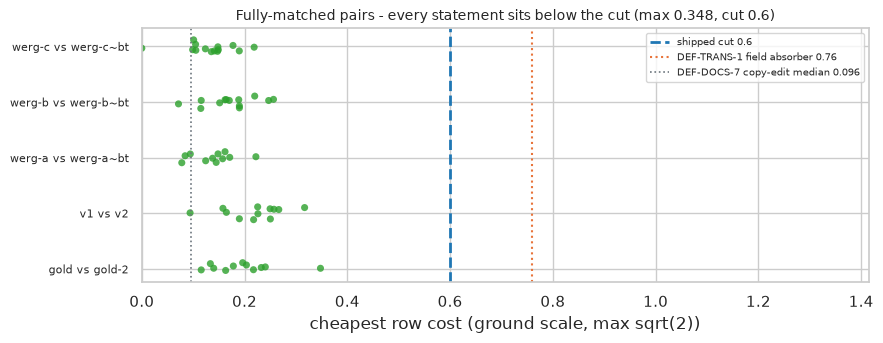

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, (a, b, _) in enumerate(FULLY_MATCHED):
    mc = matched_gate_costs[(a, b)]
    ax.scatter(mc, np.full(mc.size, i) + np.random.uniform(-0.12, 0.12, mc.size),
               color=COL["matched"], s=26, alpha=0.8, edgecolor="none")
ax.axvline(SHIPPED_CUT, color=COL["cut"], lw=2, ls="--", label=f"shipped cut {SHIPPED_CUT}")
ax.axvline(FIELD_ABSORBER_COST, color=COL["field"], lw=1.5, ls=":",
           label=f"DEF-TRANS-1 field absorber {FIELD_ABSORBER_COST}")
ax.axvline(FIELD_COPYEDIT_MEDIAN, color=COL["pool"], lw=1.2, ls=":",
           label=f"DEF-DOCS-7 copy-edit median {FIELD_COPYEDIT_MEDIAN}")
ax.set_yticks(range(len(FULLY_MATCHED)))
ax.set_yticklabels([f"{a} vs {b}" for a, b, _ in FULLY_MATCHED], fontsize=8)
ax.set_xlim(0, SMD_MAX)
ax.set_xlabel("cheapest row cost (ground scale, max sqrt(2))")
ax.set_title(f"Fully-matched pairs - every statement sits below the cut "
             f"(max {GATE_POOL_STATS['max']:.3f}, cut {SHIPPED_CUT})", fontsize=10)
ax.legend(fontsize=7, loc="upper right")
plt.tight_layout()
plt.show()

## Registered experiment - matched and removed histograms, deletion fixture

The record makes this section conditional: the kill-gate says the hypothesis is *dead before any deletion
fixture is built* if the `>0.6` band is zero on every fully-matched pair. The cell below builds the
deletion variants and both histograms only when the gate passed; otherwise it records the skip and the
reason, and no fixture is generated.

In [8]:
EXPERIMENT = {"ran": False, "reason": None}

if not GATE_PASSED:
    EXPERIMENT["reason"] = (
        f"kill-gate failed: 0/{len(GATE_ROWS_FIXTURE)} fully-matched pairs carry a nonzero >0.6 band "
        f"({GATE_TOTAL_ABOVE} of {GATE_TOTAL_ROWS} statements, pooled max {GATE_POOL_STATS['max']:.4f}). "
        "The record ends the run here - no deletion fixture is built."
    )
    console.print(Panel(EXPERIMENT["reason"], title="[bold]Registered experiment skipped[/bold]",
                        border_style="red", expand=False))
else:
    EXPERIMENT["ran"] = True
    rng = np.random.default_rng(SEED)
    matched_costs, removed_costs, matched_under_deletion = [], [], []
    for a, b in BT_PAIRS:
        _, _, mc = row_min_costs(doc_text[a], doc_text[b])
        matched_costs.append(mc)
        n_b = len(DOCSTORE[b]["statements"])
        k = max(1, int(round(DELETE_FRACTION * n_b)))
        for _s in range(DELETE_SEEDS):
            drop = np.sort(rng.choice(n_b, size=k, replace=False))
            kept = [i for i in range(n_b) if i not in set(drop.tolist())]
            b_text = "\n\n".join(DOCSTORE[b]["statements"][i] for i in kept)
            _, _, mc_d = row_min_costs(doc_text[a], b_text)
            removed_costs.append(mc_d[drop])
            matched_under_deletion.append(mc_d[kept])
    matched_costs = np.concatenate(matched_costs)
    removed_costs = np.concatenate(removed_costs)
    matched_under_deletion = np.concatenate(matched_under_deletion)
    EXPERIMENT.update(
        n_matched=int(matched_costs.size), n_removed=int(removed_costs.size),
        matched_p90=float(np.percentile(matched_costs, 90)),
        matched_above_cut_pct=float(100 * (matched_costs > SHIPPED_CUT).mean()),
        removed_below_cut_pct=float(100 * (removed_costs <= SHIPPED_CUT).mean()),
    )
    print(EXPERIMENT)

╭───────────────────────────────────────── Registered experiment skipped ─────────────────────────────────────────╮
│ kill-gate failed: 0/5 fully-matched pairs carry a nonzero >0.6 band (0 of 61 statements, pooled max 0.3477).    │
│ The record ends the run here - no deletion fixture is built.                                                    │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## By-product - pooled ibm row-min costs and the `+/- 0.15` cut sweep

Independent of the deletion fixture: pool the cheapest-row costs over all 55 ibm summary pairs (gold,
adversarial and cross-model alike, so the pool spans the whole realistic range) and sweep the cut by
`+/- 0.15`, counting how many statements change their `no_counterpart` flag against the shipped 0.6. This
absorbs the former no-counterpart cost-gap probe and says how sensitive the flag is to where the cut sits.

In [9]:
ibm_emb = {l: DD.embed_statements(path_of[l])[1] for l in ibm_labels}
ibm_pairs = list(combinations(ibm_labels, 2))

pool_rows, pool_costs = [], []
for a, b in ibm_pairs:
    mc = cost_matrix(ibm_emb[a], ibm_emb[b]).min(axis=1)
    pool_rows.append((a, b, mc))
    pool_costs.append(mc)
pool_costs = np.concatenate(pool_costs)

# faithfulness check: the derived bands must equal the shipped summary.cost_bands on every pair
shipped_bands_agree = []
for a, b, mc in pool_rows:
    _, det = DD.semantic_distance_with_details(path_of[a], path_of[b])
    shipped_bands_agree.append(band_counts(mc) == det["summary"]["cost_bands"])
POOL_BANDS_AGREE = all(shipped_bands_agree)

POOL_STATS = dict(
    n_pairs=len(ibm_pairs), n_rows=int(pool_costs.size), min=float(pool_costs.min()),
    median=float(np.median(pool_costs)), p90=float(np.percentile(pool_costs, 90)),
    p95=float(np.percentile(pool_costs, 95)), p99=float(np.percentile(pool_costs, 99)),
    max=float(pool_costs.max()), above_cut=int((pool_costs > SHIPPED_CUT).sum()),
)

base_flag = pool_costs > SHIPPED_CUT
sweep = []
for cut in SWEEP_CUTS:
    flag = pool_costs > cut
    sweep.append(dict(cut=float(cut), n_flagged=int(flag.sum()),
                      pct_flagged=float(100 * flag.mean()),
                      flips=int((flag != base_flag).sum()),
                      flips_pct=float(100 * (flag != base_flag).mean())))

t = Table(title=f"Pooled cheapest-row cost over {len(ibm_pairs)} ibm summary pairs "
                f"({POOL_STATS['n_rows']} statements)", title_style="bold cyan")
for c in ["cut", "flagged no_counterpart", "% of statements", "flips vs 0.6", "% flipped"]:
    t.add_column(c, justify="right")
for r in sweep:
    style = "bold cyan" if abs(r["cut"] - SHIPPED_CUT) < 1e-9 else None
    t.add_row(f"{r['cut']:.2f}", str(r["n_flagged"]), f"{r['pct_flagged']:.2f}",
              str(r["flips"]), f"{r['flips_pct']:.2f}", style=style)
console.print(t)

s = Table.grid(padding=(0, 2))
s.add_column(style="bold cyan")
s.add_column()
for k in ["min", "median", "p90", "p95", "p99", "max"]:
    s.add_row(k, f"{POOL_STATS[k]:.4f}")
s.add_row("above 0.6", f"{POOL_STATS['above_cut']} of {POOL_STATS['n_rows']}")
s.add_row("bands agree", str(POOL_BANDS_AGREE))
console.print(Panel(s, title="[bold]Pooled row-min statistics[/bold]", border_style="cyan", expand=False))

     Pooled cheapest-row cost over 55 ibm summary pairs (579 statements)      
┏━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━┓
┃  cut ┃ flagged no_counterpart ┃ % of statements ┃ flips vs 0.6 ┃ % flipped ┃
┡━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━┩
│ 0.45 │                     76 │           13.13 │           76 │     13.13 │
│ 0.50 │                     27 │            4.66 │           27 │      4.66 │
│ 0.55 │                     12 │            2.07 │           12 │      2.07 │
│ 0.60 │                      0 │            0.00 │            0 │      0.00 │
│ 0.65 │                      0 │            0.00 │            0 │      0.00 │
│ 0.70 │                      0 │            0.00 │            0 │      0.00 │
│ 0.75 │                      0 │            0.00 │            0 │      0.00 │
└──────┴────────────────────────┴─────────────────┴──────────────┴───────────┘

╭─ Pooled row-min statistics ─╮
│ min          0.0000         │
│ median       0.3415         │
│ p90          0.4609         │
│ p95          0.4952         │
│ p99          0.5707         │
│ max          0.5774         │
│ above 0.6    0 of 579       │
│ bands agree  True           │
╰─────────────────────────────╯

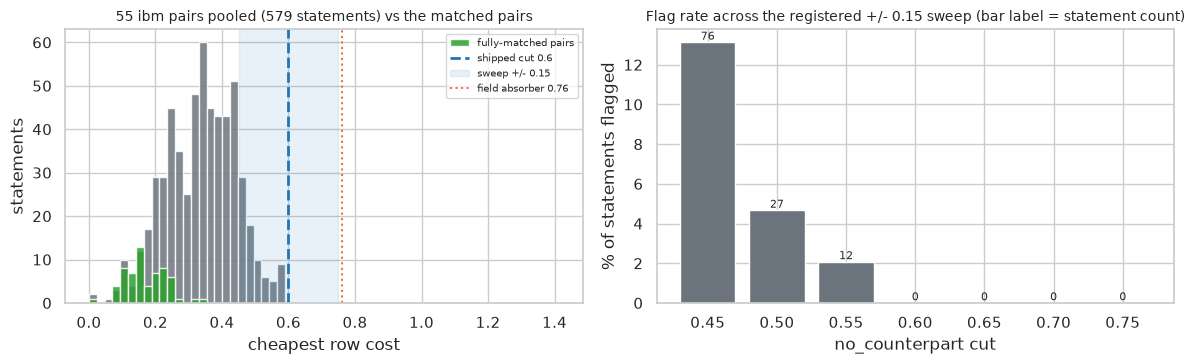

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

ax = axes[0]
ax.hist(pool_costs, bins=60, range=(0, SMD_MAX), color=COL["pool"], alpha=0.85)
ax.hist(gate_pool, bins=60, range=(0, SMD_MAX), color=COL["matched"], alpha=0.85,
        label="fully-matched pairs")
ax.axvline(SHIPPED_CUT, color=COL["cut"], lw=2, ls="--", label=f"shipped cut {SHIPPED_CUT}")
ax.axvspan(SHIPPED_CUT - SWEEP_HALFWIDTH, SHIPPED_CUT + SWEEP_HALFWIDTH, color=COL["cut"], alpha=0.10,
           label="sweep +/- 0.15")
ax.axvline(FIELD_ABSORBER_COST, color=COL["field"], lw=1.5, ls=":",
           label=f"field absorber {FIELD_ABSORBER_COST}")
ax.set_xlabel("cheapest row cost")
ax.set_ylabel("statements")
ax.set_title(f"55 ibm pairs pooled ({POOL_STATS['n_rows']} statements) vs the matched pairs", fontsize=10)
ax.legend(fontsize=7)

ax = axes[1]
cuts = [r["cut"] for r in sweep]
ax.bar([f"{c:.2f}" for c in cuts], [r["pct_flagged"] for r in sweep],
       color=[COL["cut"] if abs(c - SHIPPED_CUT) < 1e-9 else COL["pool"] for c in cuts])
for i, r in enumerate(sweep):
    ax.text(i, r["pct_flagged"], f"{r['n_flagged']}", ha="center", va="bottom", fontsize=8)
ax.set_xlabel("no_counterpart cut")
ax.set_ylabel("% of statements flagged")
ax.set_title("Flag rate across the registered +/- 0.15 sweep (bar label = statement count)", fontsize=10)
plt.tight_layout()
plt.show()

## Guardrails

Three standing guardrails, measured rather than asserted. `V` is the ordinality-violation count over the
6 gold x 4 adversarial comparisons of the ibm fixture, read off the shipped default path. Bit-identity is
measured by patching `pipe.NO_COUNTERPART_COST` to each candidate cut and comparing the resulting
`smd` / `order_gap` with `np.array_equal`, plus a byte diff of the detail JSON with only the annotation
keys removed - the semantic path (`pipeline.py:388`) and the structural path (`pipeline.py:544`, which
nulls `displacement_norm` and suppresses `moved`) are both covered. The metric property is the triangle
inequality on the pairwise `smd` matrix of the 11 ibm documents.

In [11]:
# --- V: ordinality violations on the shipped default path -------------------------------------
ibm_dist = {l: DD.semantic_distance(path_of[l], path_of[REFERENCE]).smd for l in nonref}
g = np.array([ibm_dist[l] for l in gold_labels if l != REFERENCE])
adv = np.array([ibm_dist[l] for l in adv_labels])
V = int(sum(1 for gg in g for aa in adv if gg >= aa))
V_TOTAL = int(g.size * adv.size)
V_MARGIN = float(adv.min() - g.max())
print(f"V = {V}/{V_TOTAL} | gold max {g.max():.4f} < adversarial min {adv.min():.4f} "
      f"(separation {V_MARGIN:+.4f})")

# --- bit-identity of smd / order_gap under a patched cut --------------------------------------
GUARD_PAIRS = [(doc_text[a], doc_text[b], f"{a} vs {b}") for a, b, _ in FULLY_MATCHED]
GUARD_PAIRS += [(path_of[REFERENCE], path_of[l], f"gold vs {l}")
                for l in ["opus", "sonnet", "haiku", "adv1-a", "adv2-a"]]

SEM_ANNOT = {"no_counterpart", "n_no_counterpart"}  # per-flow flag and its summary count
STR_ANNOT = {"displacement_norm", "moved", "no_counterpart", "median_displacement_norm",
             "share_target_other_section", "n_moved", "n_no_counterpart"}


def strip_annotations(det, annot):
    # deep copy with every cut-derived annotation key removed, so the rest can be byte-compared
    d = copy.deepcopy(det)
    d["thresholds"].pop("no_counterpart_cost", None)
    d["summary"] = {k: v for k, v in d["summary"].items() if k not in annot}
    for key in ("flows", "statements", "sections"):
        if key in d:
            d[key] = [{k: v for k, v in rec.items() if k not in annot} for rec in d[key]]
    return json.dumps(d, sort_keys=True)


def measure(cut):
    pipe.NO_COUNTERPART_COST = cut
    sem_smd, str_gap, sem_json, str_json, n_sem_flag, n_str_flag = [], [], [], [], 0, 0
    for a, b, _lbl in GUARD_PAIRS:
        r, d = DD.semantic_distance_with_details(a, b)
        sr, sd = DD.structural_distance_with_details(a, b)
        sem_smd.append(r.smd)
        str_gap.append(sr.order_gap)
        sem_json.append(strip_annotations(d, SEM_ANNOT))
        str_json.append(strip_annotations(sd, STR_ANNOT))
        n_sem_flag += d["summary"]["n_no_counterpart"]
        n_str_flag += sd["summary"]["n_no_counterpart"]
    return dict(smd=np.array(sem_smd), gap=np.array(str_gap), sem=sem_json, str=str_json,
                n_sem_flag=n_sem_flag, n_str_flag=n_str_flag)


base = measure(SHIPPED_CUT)
guard_rows = []
for cut in CANDIDATE_CUTS:
    m = measure(cut)
    guard_rows.append(dict(
        cut=cut,
        smd_identical=bool(np.array_equal(base["smd"], m["smd"])),
        gap_identical=bool(np.array_equal(base["gap"], m["gap"])),
        sem_json_identical=all(x == y for x, y in zip(base["sem"], m["sem"])),
        str_json_identical=all(x == y for x, y in zip(base["str"], m["str"])),
        sem_flags=m["n_sem_flag"], str_flags=m["n_str_flag"],
    ))
pipe.NO_COUNTERPART_COST = SHIPPED_CUT  # restore the shipped value
assert pipe.NO_COUNTERPART_COST == SHIPPED_CUT

SMD_BIT_IDENTICAL = all(r["smd_identical"] and r["sem_json_identical"] for r in guard_rows)
GAP_BIT_IDENTICAL = all(r["gap_identical"] and r["str_json_identical"] for r in guard_rows)

t = Table(title=f"Annotation-only guardrail over {len(GUARD_PAIRS)} pairs "
                f"(shipped cut flags {base['n_sem_flag']} semantic / {base['n_str_flag']} structural)",
          title_style="bold cyan")
for c in ["patched cut", "smd array_equal", "order_gap array_equal", "semantic JSON byte-identical",
          "structural JSON byte-identical", "semantic flags", "structural flags"]:
    t.add_column(c, justify="right")
for r in guard_rows:
    t.add_row(f"{r['cut']:.2f}", str(r["smd_identical"]), str(r["gap_identical"]),
              str(r["sem_json_identical"]), str(r["str_json_identical"]),
              str(r["sem_flags"]), str(r["str_flags"]))
console.print(t)

# --- metric property: triangle inequality on the pairwise smd matrix --------------------------
n = len(ibm_labels)
D = np.zeros((n, n))
for i, j in combinations(range(n), 2):
    d = float(ot.emd2(np.full(len(ibm_emb[ibm_labels[i]]), 1 / len(ibm_emb[ibm_labels[i]])),
                      np.full(len(ibm_emb[ibm_labels[j]]), 1 / len(ibm_emb[ibm_labels[j]])),
                      cost_matrix(ibm_emb[ibm_labels[i]], ibm_emb[ibm_labels[j]])))
    D[i, j] = D[j, i] = d
TRI_TOL = 1e-9
tri_total = tri_viol = 0
for i, j, k in combinations(range(n), 3):
    for x, y, z in ((i, j, k), (j, k, i), (k, i, j)):
        tri_total += 1
        if D[x, y] > D[x, z] + D[z, y] + TRI_TOL:
            tri_viol += 1
METRIC_OK = tri_viol == 0
print(f"triangle inequality: {tri_viol} violations in {tri_total} checks over "
      f"{len(list(combinations(range(n), 3)))} triples (tol {TRI_TOL})")
print(f"smd bit-identical under every patched cut: {SMD_BIT_IDENTICAL} | "
      f"order_gap bit-identical: {GAP_BIT_IDENTICAL}")

V = 0/24 | gold max 0.2907 < adversarial min 0.3573 (separation +0.0666)


               Annotation-only guardrail over 10 pairs (shipped cut flags 0 semantic / 0 structural)               
┏━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃             ┃                ┃                ┃                ┃    structural ┃                ┃               ┃
┃             ┃            smd ┃      order_gap ┃  semantic JSON ┃          JSON ┃                ┃    structural ┃
┃ patched cut ┃    array_equal ┃    array_equal ┃ byte-identical ┃ byte-identic… ┃ semantic flags ┃         flags ┃
┡━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│        0.45 │           True │           True │           True │          True │              6 │             7 │
│        0.70 │           True │           True │           True │          True │              0 │             0 │
│        0.75 │           True │           True │           True │          True │              0 │             0 │
└─────────────┴────────────────┴────────────────┴────────────────┴───────────────┴────────────────┴───────────────┘

triangle inequality: 0 violations in 495 checks over 165 triples (tol 1e-09)
smd bit-identical under every patched cut: True | order_gap bit-identical: True


## Acceptance bar

The registered bar is PASS (defect confirmed) if more than 2% of ground-truth-matched statements exceed
0.6 while fewer than 5% of true-removed statements fall below it. It is evaluated only when the deletion
fixture was built; a failed kill-gate ends the run before either population exists, and the verdict is
`Killed-at-gate` on the gate reading rather than a PASS or FAIL of this bar.

In [12]:
if EXPERIMENT["ran"]:
    BAR_MET = (EXPERIMENT["matched_above_cut_pct"] > 2.0) and (EXPERIMENT["removed_below_cut_pct"] < 5.0)
    bar_reading = (f"matched > 0.6: {EXPERIMENT['matched_above_cut_pct']:.2f}% (bar > 2%); "
                   f"removed <= 0.6: {EXPERIMENT['removed_below_cut_pct']:.2f}% (bar < 5%)")
else:
    BAR_MET = False
    bar_reading = ("not evaluated - the kill-gate ended the run before the matched and removed "
                   "populations were built")

VERDICT = "Killed-at-gate" if not GATE_PASSED else ("Confirmed" if BAR_MET else "Refuted")
VERDICT_NUMBER = (
    f"{GATE_PAIRS_NONZERO} of {len(GATE_ROWS_FIXTURE)} fully-matched pairs with a nonzero >0.6 band "
    f"({GATE_TOTAL_ABOVE} of {GATE_TOTAL_ROWS} statements above {SHIPPED_CUT}; "
    f"pooled matched maximum {GATE_POOL_STATS['max']:.4f})"
) if not GATE_PASSED else bar_reading

console.print(Panel(f"[bold]{VERDICT}[/bold]\n{VERDICT_NUMBER}\n\nacceptance bar: {bar_reading}",
                    title="[bold]E12-H60 verdict[/bold]",
                    border_style="red" if VERDICT == "Killed-at-gate" else "green", expand=False))

╭──────────────────────────────────────────────── E12-H60 verdict ────────────────────────────────────────────────╮
│ Killed-at-gate                                                                                                  │
│ 0 of 5 fully-matched pairs with a nonzero >0.6 band (0 of 61 statements above 0.6; pooled matched maximum       │
│ 0.3477)                                                                                                         │
│                                                                                                                 │
│ acceptance bar: not evaluated - the kill-gate ended the run before the matched and removed populations were     │
│ built                                                                                                           │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Metrics JSON

Every measured number, the bar readings and the guardrail readings, written to
`reports/E12-H60-no-counterpart-valley-metrics.json`.

In [13]:
metrics = {
    "id": "E12-H60",
    "slug": "no-counterpart-valley",
    "generated": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "docdistance_version": pipe._VERSION,
    "verdict": VERDICT,
    "verdict_number": VERDICT_NUMBER,
    "config": {
        "shipped_cut": SHIPPED_CUT,
        "smd_max": float(SMD_MAX),
        "cost_band_edges": COST_BAND_EDGES,
        "sweep_cuts": SWEEP_CUTS,
        "candidate_cuts": CANDIDATE_CUTS,
        "delete_fraction": DELETE_FRACTION,
        "delete_seeds": DELETE_SEEDS,
        "seed": SEED,
        "backend": "openvino-int8-cpu",
        "fully_matched_pairs": [f"{a} vs {b}" for a, b, _ in FULLY_MATCHED],
        "roundtrip_exact": bool(ROUNDTRIP_OK),
        "roundtrip": {k: {"n_fixture": v[0], "n_resegmented": v[1], "text_equal": bool(v[2])}
                      for k, v in roundtrip.items()},
    },
    "kill_gate": {
        "rule": "summary.cost_bands['>0.6'] on the fully-matched pairs only; zero everywhere kills",
        "passed": bool(GATE_PASSED),
        "pairs_with_nonzero_band": GATE_PAIRS_NONZERO,
        "n_pairs": len(GATE_ROWS_FIXTURE),
        "statements_above_cut": GATE_TOTAL_ABOVE,
        "statements_total": GATE_TOTAL_ROWS,
        "all_readings_zero_including_file_reading": bool(GATE_ALL_READINGS_ZERO),
        "derived_bands_match_shipped": bool(GATE_BANDS_AGREE),
        "rows": [{k: v for k, v in r.items()} for r in gate_rows],
        "pooled_row_min": GATE_POOL_STATS,
    },
    "registered_experiment": EXPERIMENT,
    "byproduct_ibm_pool": {
        "stats": POOL_STATS,
        "derived_bands_match_shipped": bool(POOL_BANDS_AGREE),
        "sweep": sweep,
    },
    "acceptance": {
        "bar": ("PASS if >2% of ground-truth-matched statements exceed 0.6 while <5% of true-removed "
                "statements fall below it"),
        "met": bool(BAR_MET),
        "reading": bar_reading,
    },
    "guardrails": {
        "V": f"{V}/{V_TOTAL}",
        "V_separation": V_MARGIN,
        "smd_bit_identical": bool(SMD_BIT_IDENTICAL),
        "order_gap_bit_identical": bool(GAP_BIT_IDENTICAL),
        "metric_property_triangle_violations": tri_viol,
        "metric_property_checks": tri_total,
        "metric_property_ok": bool(METRIC_OK),
        "guard_pairs": [lbl for _, _, lbl in GUARD_PAIRS],
        "rows": guard_rows,
        "shipped_cut_flags": {"semantic": base["n_sem_flag"], "structural": base["n_str_flag"]},
    },
    "field_anchors": {
        "def_trans_1_synthetic_removal_cost": FIELD_SYNTH_COST,
        "def_trans_1_field_absorber_cost": FIELD_ABSORBER_COST,
        "def_docs_7_copyedit_median_cost": FIELD_COPYEDIT_MEDIAN,
        "e11_backtranslation_smd": E11_BT_SMD,
        "note": ("re-derived from docs/defects-docdistance.md, the corrected recount; the "
                 "corrections.json forensics archive is not present in this repository"),
    },
}
REPORT.write_text(json.dumps(metrics, indent=2) + "\n")
print(f"wrote {REPORT} ({REPORT.stat().st_size} bytes)")
print(json.dumps({k: metrics[k] for k in ["verdict", "verdict_number", "acceptance"]}, indent=2))

wrote /home/lab/workspace/learning/projects/docdistance/reports/E12-H60-no-counterpart-valley-metrics.json (9838 bytes)
{
  "verdict": "Killed-at-gate",
  "verdict_number": "0 of 5 fully-matched pairs with a nonzero >0.6 band (0 of 61 statements above 0.6; pooled matched maximum 0.3477)",
  "acceptance": {
    "bar": "PASS if >2% of ground-truth-matched statements exceed 0.6 while <5% of true-removed statements fall below it",
    "met": false,
    "reading": "not evaluated - the kill-gate ended the run before the matched and removed populations were built"
  }
}


## Conclusions

**Verdict - `Killed-at-gate`.** The registered kill-gate reads `summary.cost_bands[">0.6"]` on the
fully-matched pairs only, and it is zero on every one of them: **0 of 5 pairs** carry a nonzero band,
**0 of 61 statements** exceed the shipped 0.6 cut, and the pooled matched maximum is **0.3477** - a
headroom of **0.2523** below the cut. The same reading through the file path the CLI uses (which drops the
`# ` title line, so `gold vs gold-2` segments 10 vs 12 instead of 11 vs 13) is also zero, so the result is
not an artefact of handing the fixture text to the API. The record's own stopping rule applies: no
over-firing exists on construction-guaranteed matched content, so no deletion fixture was built and the
acceptance bar was never evaluated.

**The prediction is falsified in its own direction.** It expected matched cheapest-row costs
right-skewed with a 90th percentile near 0.45-0.55 and 3-10% of matched statements above 0.6. The measured
matched population sits far lower - median **0.1631**, p90 **0.2496**, p95 **0.2572**, maximum **0.3477** -
and **0%** cross the cut. The two populations do not approach each other on this evidence; the matched
population stops well short of the cut.

**The by-product widens that reading past the fully-matched pairs.** Over all 55 ibm summary pairs
(**579 statements**, including cross-model and adversarial pairs that legitimately omit content) the
cheapest-row cost tops out at **0.5774**, with p99 **0.5707** - still below 0.6. The registered
`+/- 0.15` sweep therefore flips nothing upward and everything downward: **0** statements flagged at 0.60
through 0.75, **12** (2.07%) at 0.55, **27** (4.66%) at 0.50, **76** (13.13%) at 0.45. The shipped cut sits
**0.023** above the largest cheapest-row cost this corpus produces, so on these fixtures the
`no_counterpart` flag is inert rather than over-firing.

**Guardrails hold, measured not asserted.** `V = 0/24` on the shipped default path, with the gold maximum
below the adversarial minimum by **+0.0666**. Patching `pipe.NO_COUNTERPART_COST` to 0.45, 0.70 and 0.75
over 10 pairs leaves `smd` and `order_gap` equal under `np.array_equal` at every cut, and both the semantic
and the structural detail JSON byte-identical once the cut-derived annotation keys are removed - while the
0.45 patch does fire **6** semantic and **7** structural flags, so the comparison is against a cut that
genuinely changed the annotations. The triangle inequality holds with **0 violations in 495 checks** over
the 165 triples of the 11 ibm documents.

**What is closed and what is not.** The gate closes the over-firing question the hypothesis raised: on
construction-guaranteed matched content the flag does not fire falsely, and the DEF-TRANS-1 field absorber
at 0.76 remains above every matched cost measured here. It does not measure the valley itself. No
true-removed population was scored, so the density minimum between the matched and removed modes stays
unlocated, and the corpus offers no evidence about where between 0.5774 and 0.76 the boundary belongs. A
cut lowered into the 0.50-0.55 region would begin annotating real ibm statements, which is the sensitivity
the sweep quantifies but not a recommendation - the removed-side mass that would justify a move was never
generated. `NO_COUNTERPART_COST` stays at 0.6 and the question of its exact placement is deferred, not
answered.